In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
# 1. Загружаем данные из файла
df = pd.read_csv(r'C:\Users\gurge\PycharmProjects\pythonProject\BNPL_ecom_project\orders.csv')

# Посмотрим на первые строки и узнаем базовую инфу
print(df.head())
print(f"Всего строк в таблице: {len(df)}")

   order_id    user_id           order_date  product_id  \
0         1  543272936  2019-10-01 00:02:14     1004856   
1         2  551377651  2019-10-01 00:04:37     1002532   
2         3  514591159  2019-10-01 00:06:02     5100816   
3         4  555332717  2019-10-01 00:07:07    13800054   
4         5  524601178  2019-10-01 00:09:26     4804055   

                 category_code    brand   price payment_method  
0       electronics.smartphone  samsung  130.76           bnpl  
1       electronics.smartphone    apple  642.69           card  
2                          NaN   xiaomi   29.51           card  
3    furniture.bathroom.toilet  santeri   54.42           card  
4  electronics.audio.headphone    apple  189.91           bnpl  
Всего строк в таблице: 9758


In [7]:
# 3. Сегментируем BNPL-заказы по сумме чека
# Оставляем только BNPL
df_bnpl = df[df['payment_method'] == 'bnpl'].copy()

# Разбиваем на группы по цене
# ВАЖНО: Судя по данным, цены указаны в долларах/евро (например, 130.76), поэтому границы ставим меньше
bins = [0, 100, 500, float('inf')]
labels = ['Низкий (<100)', 'Средний (100-500)', 'Высокий (>500)']
df_bnpl['amount_group'] = pd.cut(df_bnpl['price'], bins=bins, labels=labels)

# Считаем метрики по новым группам
amount_stats = df_bnpl.groupby('amount_group', observed=False).agg(
    total_transactions=('order_id', 'count'),
    aov=('price', 'mean'),
    total_revenue=('price', 'sum')
).reset_index()

amount_stats['aov'] = amount_stats['aov'].round(2)
print("\nМетрики BNPL по размеру чека:")
print(amount_stats)


Метрики BNPL по размеру чека:
        amount_group  total_transactions     aov  total_revenue
0      Низкий (<100)                   0     NaN           0.00
1  Средний (100-500)                2547  234.19      596483.41
2     Высокий (>500)                1006  928.68      934250.65


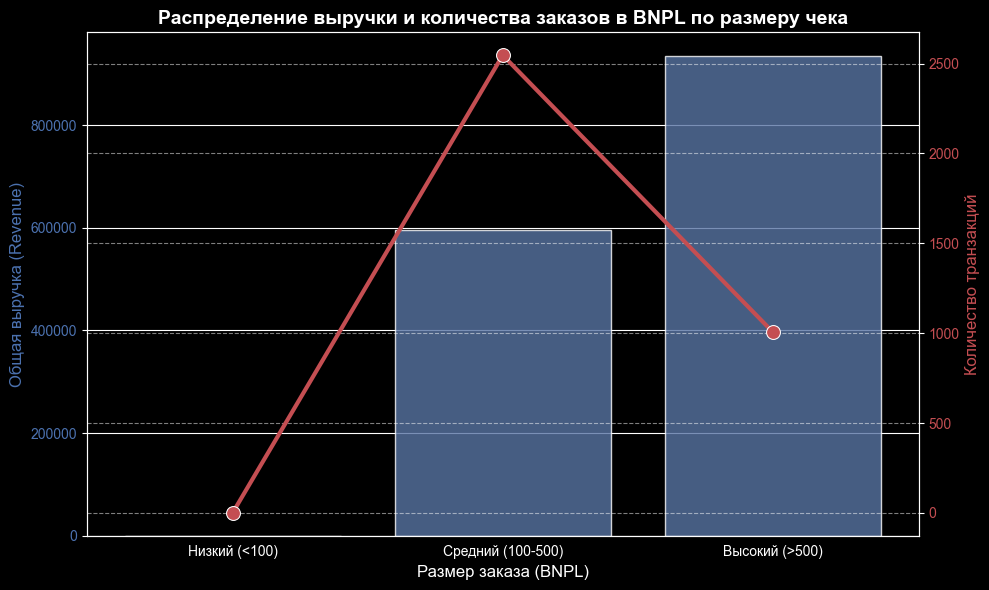

In [8]:
# 4. Строим комбо-график (Столбцы - Выручка, Линия - Количество заказов)
fig, ax1 = plt.subplots(figsize=(10, 6))

# Столбцы для выручки
sns.barplot(x='amount_group', y='total_revenue', data=amount_stats, ax=ax1, color='#4C72B0', alpha=0.8)
ax1.set_ylabel('Общая выручка (Revenue)', color='#4C72B0', fontsize=12)
ax1.set_xlabel('Размер заказа (BNPL)', fontsize=12)
ax1.tick_params(axis='y', labelcolor='#4C72B0')

# Линия для количества транзакций
ax2 = ax1.twinx()
sns.lineplot(x='amount_group', y='total_transactions', data=amount_stats, ax=ax2, color='#C44E52', marker='o', linewidth=3, markersize=10)
ax2.set_ylabel('Количество транзакций', color='#C44E52', fontsize=12)
ax2.tick_params(axis='y', labelcolor='#C44E52')

plt.title('Распределение выручки и количества заказов в BNPL по размеру чека', fontsize=14, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()

# Сохраняем график (он пригодится для GitHub)
plt.savefig('bnpl_amount_segmentation.png', dpi=300, bbox_inches='tight')
plt.show()